# Plan or Learn? Dynamic pricing of airline tickets under model error

Imane Amraoui and Dia Eddine Kadri — Reinforcement Learning course (J. Martinet), Polytech SI5-IAID, 2026–2027.

This notebook walks through the project and shows its main results. It reuses the code of `src/`
(the same code tested by `pytest`) and the results produced by the scripts of `experiments/`
(see `README.md`). Everything here runs in about one minute; only the long experiments
(10 seeds × 7 budgets) are read from their CSV files instead of being rerun.

**Research question:** from which model error does learning without a model (Q-learning) outperform
planning with a wrong one (Dynamic Programming), for a given budget of episodes?

In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

ROOT = os.path.abspath("..")
sys.path.insert(0, os.path.join(ROOT, "src"))
RESULTS = os.path.join(ROOT, "results")
FIGURES = os.path.join(RESULTS, "figures")

from demand import DemandModel
from env import AirlineEnv
from dp import solve_dp, as_policy
from evaluate import evaluate_exact, evaluate_mc
from baselines import best_fixed_price, best_rising_price
from qlearning import train_qlearning, greedy_policy
from sarsa import train_sarsa
from plots import plot_policy

PRICES = [50, 80, 110, 140, 170, 200]

## 1. The MDP

- **State** $(c, t)$: $c \in \{0..10\}$ seats left, $t \in \{0..30\}$ days to departure (341 states).
- **Actions**: six prices, 50 to 200 €.
- **Reward**: price × seats sold that day; the episode ends at $t = 0$ or $c = 0$; $\gamma = 1$.
- **Demand**: leisure customers (mean willingness to pay 80 €) arrive mostly early, business customers
  (mean 180 €) in the last 10 days. A customer buys with probability $e^{-p/m}$, so the daily demand is
  Poisson with mean $\mu = \lambda_L e^{-p/m_L} + \lambda_B e^{-p/m_B}$, and sales are $\min(D, c)$.

Expected daily demand for each price, before and after the arrival of business customers:

In [2]:
model = DemandModel()
pd.DataFrame({"price (€)": PRICES,
              "demand, t = 20": [round(model.expected_demand(20, p), 3) for p in PRICES],
              "demand, t = 5": [round(model.expected_demand(5, p), 3) for p in PRICES]})

,price (€),"demand, t = 20","demand, t = 5"
0,50,0.504,0.918
1,80,0.358,0.752
2,110,0.257,0.619
3,140,0.185,0.512
4,170,0.134,0.425
5,200,0.099,0.354


The simulator only exposes `reset()` and `step(action)`: this is all a model-free agent sees.

In [3]:
env = AirlineEnv(model, seed=0)
state = env.reset()
print("start:", state)
for _ in range(3):
    state, reward, done = env.step(4)   # price 170 €
    print("state", state, "reward", reward, "done", done)

start: (10, 30)
state (10, 29) reward 0.0 done False
state (10, 28) reward 0.0 done False
state (10, 27) reward 0.0 done False


## 2. Planning: Dynamic Programming on the true model

Bellman optimality, $V^*(c,t)=\max_a \sum_k P(k\mid c,t,a)\,[p_a k + V^*(c-k,t-1)]$.
Since $V^*(\cdot,t)$ only depends on $V^*(\cdot,t-1)$, one backward sweep gives the exact optimum.

In [4]:
V, dp_table = solve_dp(model)
dp_policy = as_policy(dp_table)
exact = evaluate_exact(dp_policy, model)
mc = evaluate_mc(dp_policy, model, n_flights=10_000, seed=0)
half = 1.96 * mc.revenue_std / np.sqrt(mc.n_flights)
print(f"DP value V*(10, 30)          : {V[10, 30]:.1f} €")
print(f"Exact policy evaluation      : {exact.revenue:.1f} €, load {exact.load_factor:.0%}, sold out {exact.sold_out:.1%}")
print(f"Monte-Carlo, 10 000 flights  : {mc.revenue:.1f} € ± {half:.1f} (95 % CI)")

DP value V*(10, 30)          : 1193.5 €
Exact policy evaluation      : 1193.5 €, load 77%, sold out 22.8%
Monte-Carlo, 10 000 flights  : 1191.5 € ± 6.8 (95 % CI)


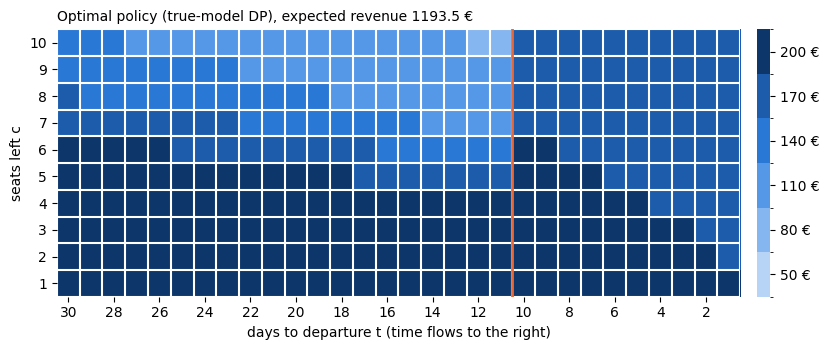

In [5]:
fig, ax = plt.subplots(figsize=(9, 3.6))
plot_policy(dp_policy, ax=ax, title=f"Optimal policy (true-model DP), expected revenue {V[10, 30]:.1f} €")
plt.tight_layout(); plt.show()

The price never increases with the number of seats left (as in Gallego & van Ryzin, 1994), jumps when
business customers arrive ($t = 10$), and drops to 80 € just before to sell the remaining seats to leisure customers.

## 3. Baselines

In [6]:
optimum = exact.revenue
a, fixed = best_fixed_price(model)
(s, e), rising = best_rising_price(model)
pd.DataFrame([
    ["DP (optimum)", optimum, 100.0],
    [f"Rising price {PRICES[s]} -> {PRICES[e]} €", rising.revenue, 100 * rising.revenue / optimum],
    [f"Fixed price {PRICES[a]} €", fixed.revenue, 100 * fixed.revenue / optimum],
], columns=["policy", "revenue (€)", "% of optimum"]).round(1)

,policy,revenue (€),% of optimum
0,DP (optimum),1193.5,100.0
1,Rising price 140 -> 170 €,1166.1,97.7
2,Fixed price 170 €,1146.7,96.1


## 4. Learning: Q-learning without a model

Tabular Q-learning, $\varepsilon$-greedy ($\varepsilon$ from 1 to 0.01), step size
$\alpha_n = 0.5/(1+40\,n/N)$. One run of 30 000 episodes (one seed) as a live demonstration;
the learned greedy policy is evaluated exactly on the true model.

Q-learning, 30 000 episodes, seed 0: 1135.8 € = 95.2 % of the optimum


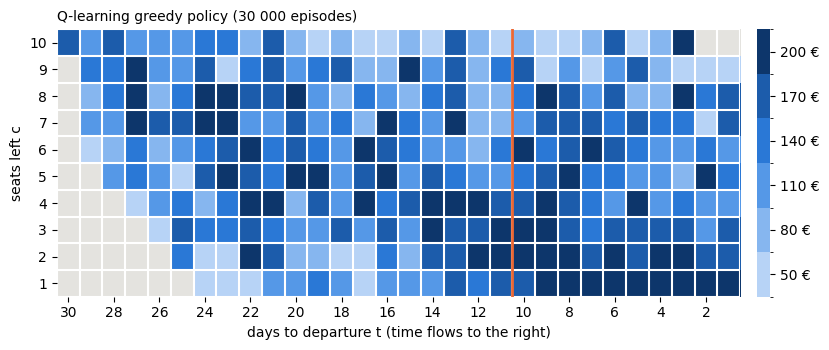

In [7]:
Q = train_qlearning(model, n_episodes=30_000, seed=0)
ql = evaluate_exact(greedy_policy(Q), model)
print(f"Q-learning, 30 000 episodes, seed 0: {ql.revenue:.1f} € = {100 * ql.revenue / optimum:.1f} % of the optimum")

fig, ax = plt.subplots(figsize=(9, 3.6))
plot_policy(greedy_policy(Q), ax=ax, title="Q-learning greedy policy (30 000 episodes)",
            unseen=np.all(Q == 0, axis=2))
plt.tight_layout(); plt.show()

## 5. Results of the experiments (10 seeds, 95 % confidence intervals)

These come from `experiments/e1_convergence.py`, `e2_crossover.py`, `e4_comparison.py` and
`aggregate.py` (too long to rerun here).

### E1 — How many episodes does learning need?

In [8]:
ci = pd.read_csv(os.path.join(RESULTS, "summary_ci.csv"))
e1 = ci[ci.experiment == "E1"].copy()
e1["budget"] = e1.setting.str.split("=").str[1].astype(int)
e1["result"] = e1.apply(lambda r: f"{r.mean_pct:.1f}  [{r.ci95_low:.1f}, {r.ci95_high:.1f}]", axis=1)
e1.pivot(index="budget", columns="method", values="result")

method,qlearning,sarsa
budget,,
100,"62.5 [61.4, 63.6]","60.3 [58.2, 62.4]"
300,"75.6 [73.3, 77.9]","70.7 [68.6, 72.9]"
1000,"81.4 [79.8, 83.0]","81.0 [78.5, 83.5]"
3000,"87.0 [85.8, 88.2]","85.0 [84.3, 85.6]"
10000,"93.6 [93.2, 94.1]","91.0 [90.4, 91.7]"
30000,"95.6 [95.3, 96.0]","94.9 [94.5, 95.2]"
100000,"96.4 [95.9, 96.9]","96.4 [96.2, 96.6]"


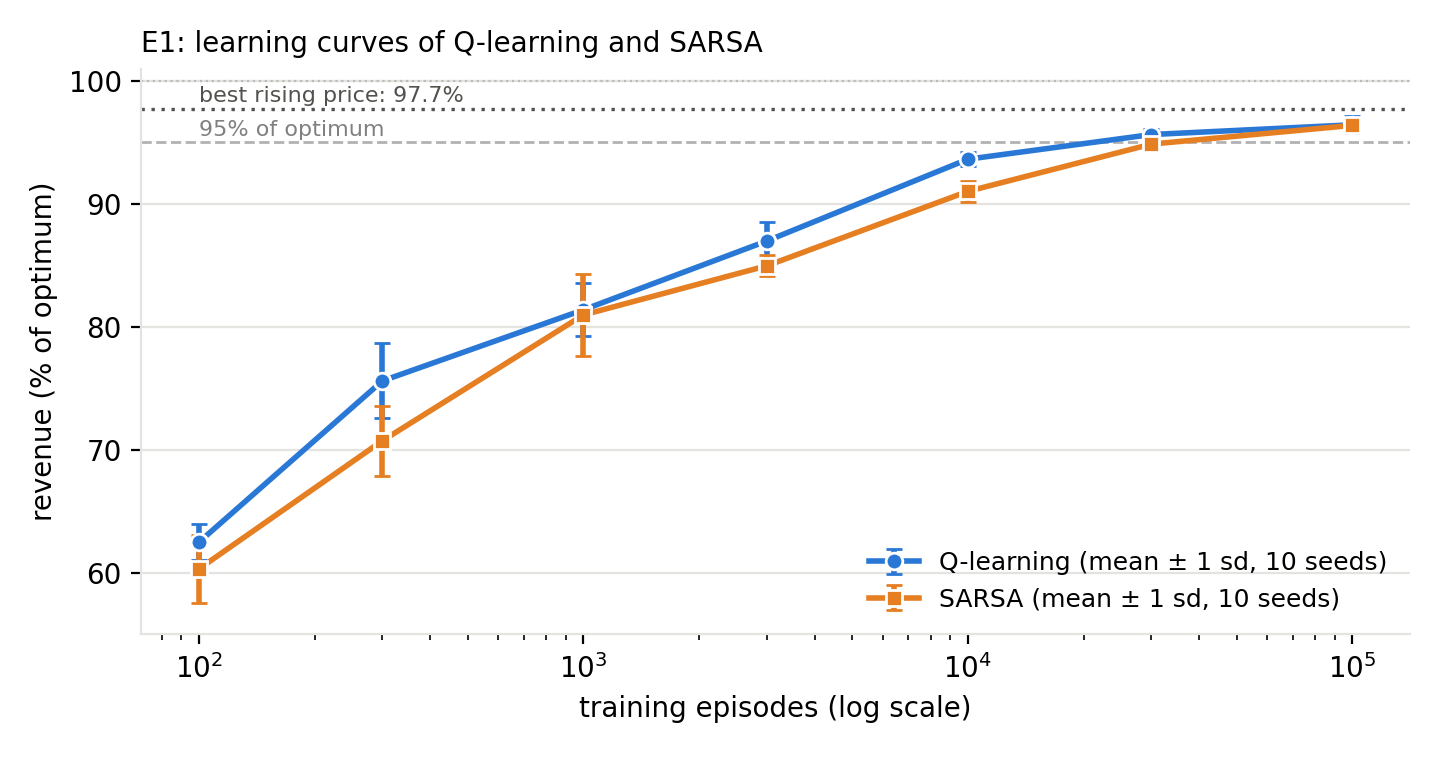

In [9]:
display(Image(os.path.join(FIGURES, "e1_convergence.png"), width=750))

Q-learning reaches 95 % of the optimum from 30 000 episodes. At 100 000 episodes both methods plateau
at 96.4 %, significantly below the rising-price rule (97.7 %).

### E2 — Planning with a wrong model vs learning

The DP plans with both willingness-to-pay means multiplied by $(1 + x)$; its policy is scored on the true model.

In [10]:
e2 = pd.read_csv(os.path.join(RESULTS, "e2_dp_side.csv"))
e2["x (%)"] = (100 * e2.x).round().astype(int)
e2[["x (%)", "dp_pct", "rising_pct"]].rename(columns={"dp_pct": "wrong DP (% opt.)",
                                                  "rising_pct": "rising price tuned on wrong model"}).round(1)

,x (%),wrong DP (% opt.),rising price tuned on wrong model
0,-50,75.8,66.0
1,-45,82.4,75.2
2,-40,85.9,75.2
3,-35,89.1,75.2
4,-30,91.9,83.7
5,-25,94.7,92.4
6,-20,97.1,92.4
7,-15,98.4,96.1
8,-10,99.2,96.1
9,-5,99.8,97.7


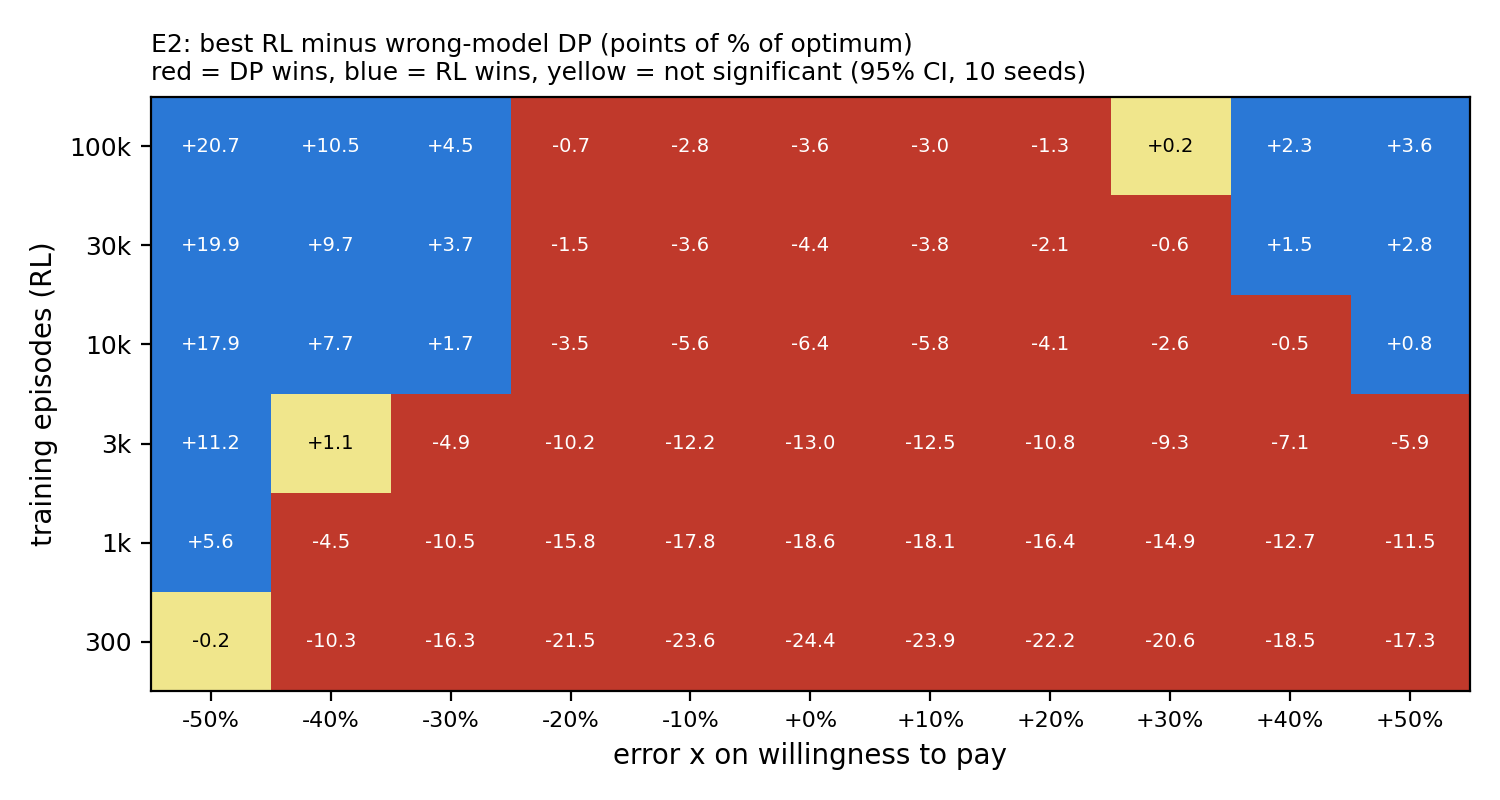

In [11]:
display(Image(os.path.join(FIGURES, "e2_winner_map.png"), width=750))

Blue: RL significantly better than the wrong DP (lower bound of its 95 % CI above the DP score);
red: DP better; yellow: not significant. Learning only wins for large errors: $x \le -30\,\%$ (from
$10^3$–$10^4$ episodes) or $x \ge +40\,\%$ ($10^4$–$3\cdot10^4$). For $-20\,\% \le x \le +30\,\%$
the DP wins or ties at every budget.

### E3 — Policies learned by Q-learning and SARSA

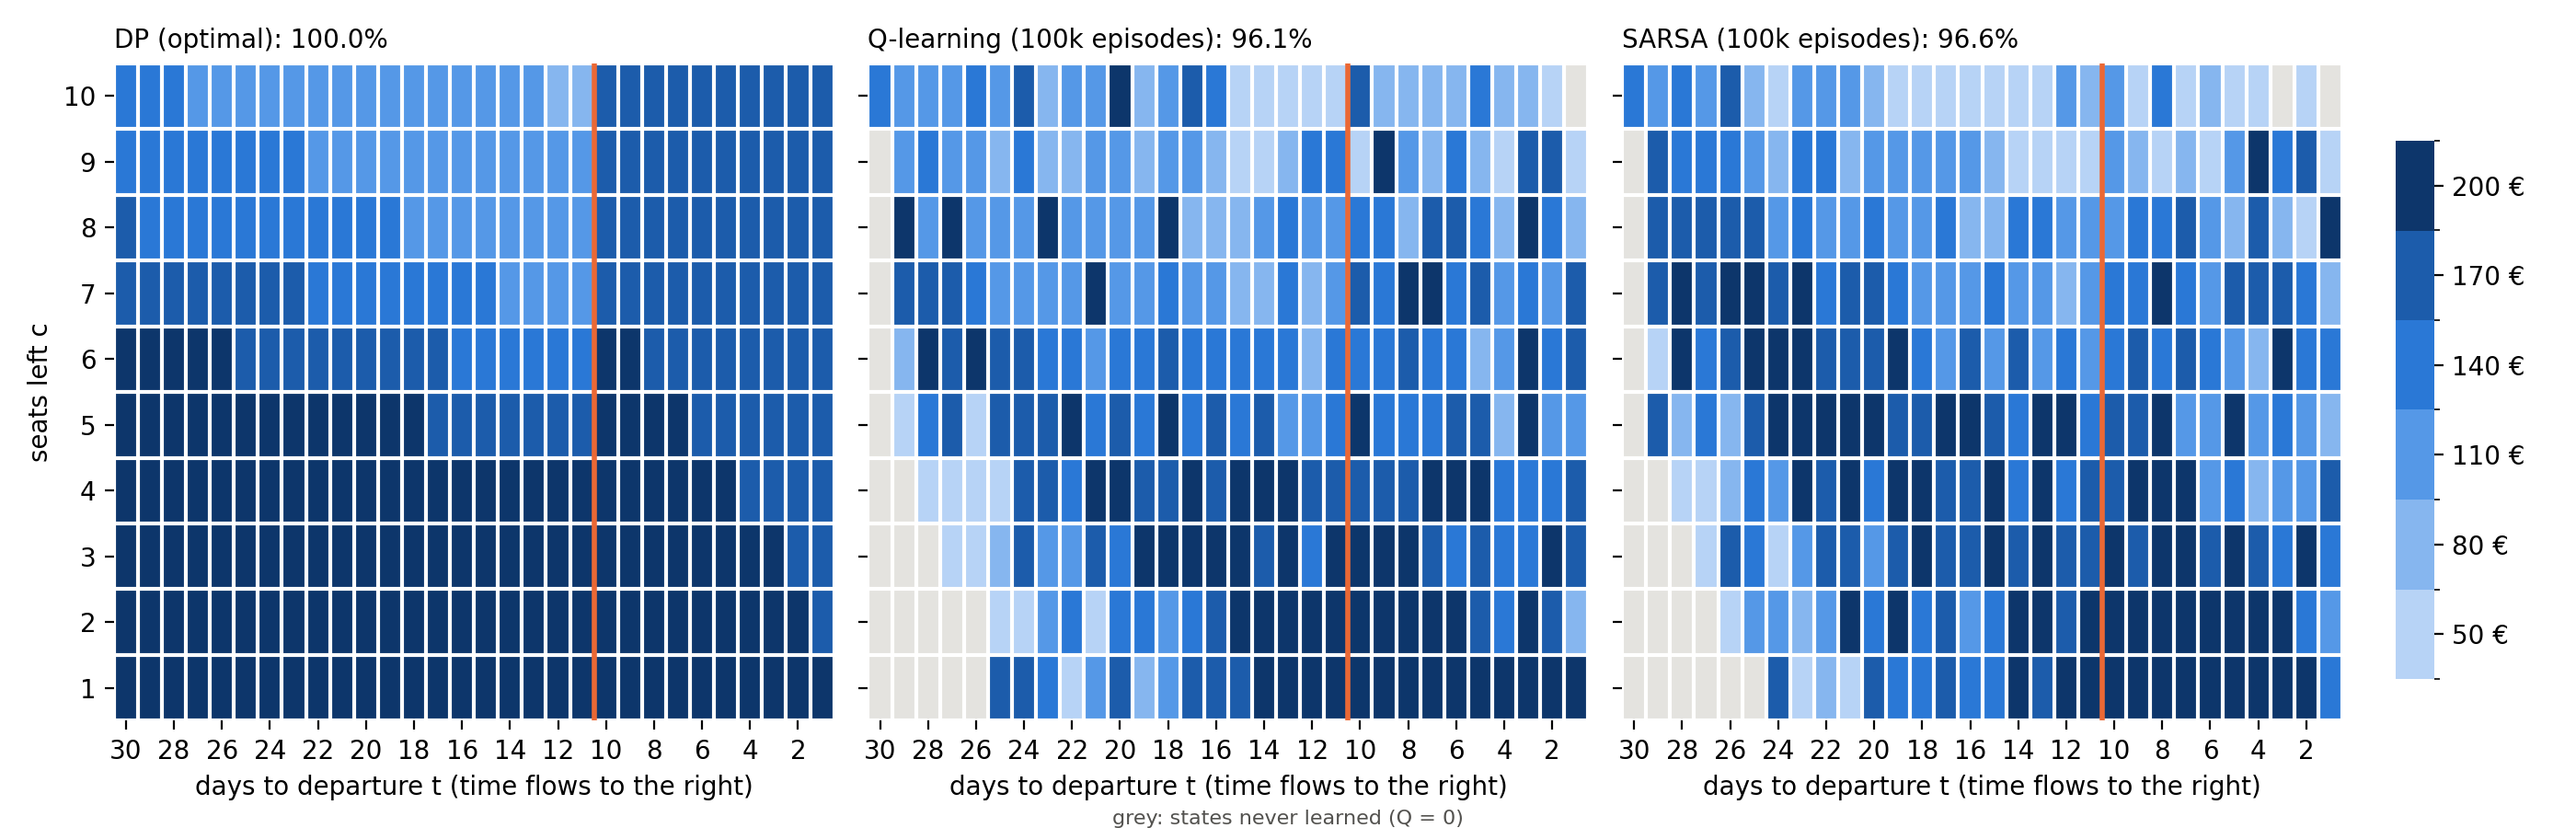

In [12]:
display(Image(os.path.join(FIGURES, "e3_policy_heatmaps.png"), width=900))

### E4 — Discount factor

A policy optimised with $\gamma < 1$ is evaluated on the real, undiscounted revenue.

In [13]:
e4 = pd.read_csv(os.path.join(RESULTS, "e4_comparison.csv"))
e4.groupby(["method", "gamma"]).pct_optimum.agg(["mean", "std", "count"]).round(1)

mean  std  count
method     gamma                   
DP         0.5     83.7  NaN      1
           0.9     97.8  NaN      1
           1.0    100.0  NaN      1
Q-learning 0.5     74.7  1.8     10
           0.9     89.7  1.1     10
           1.0     95.6  0.5     10

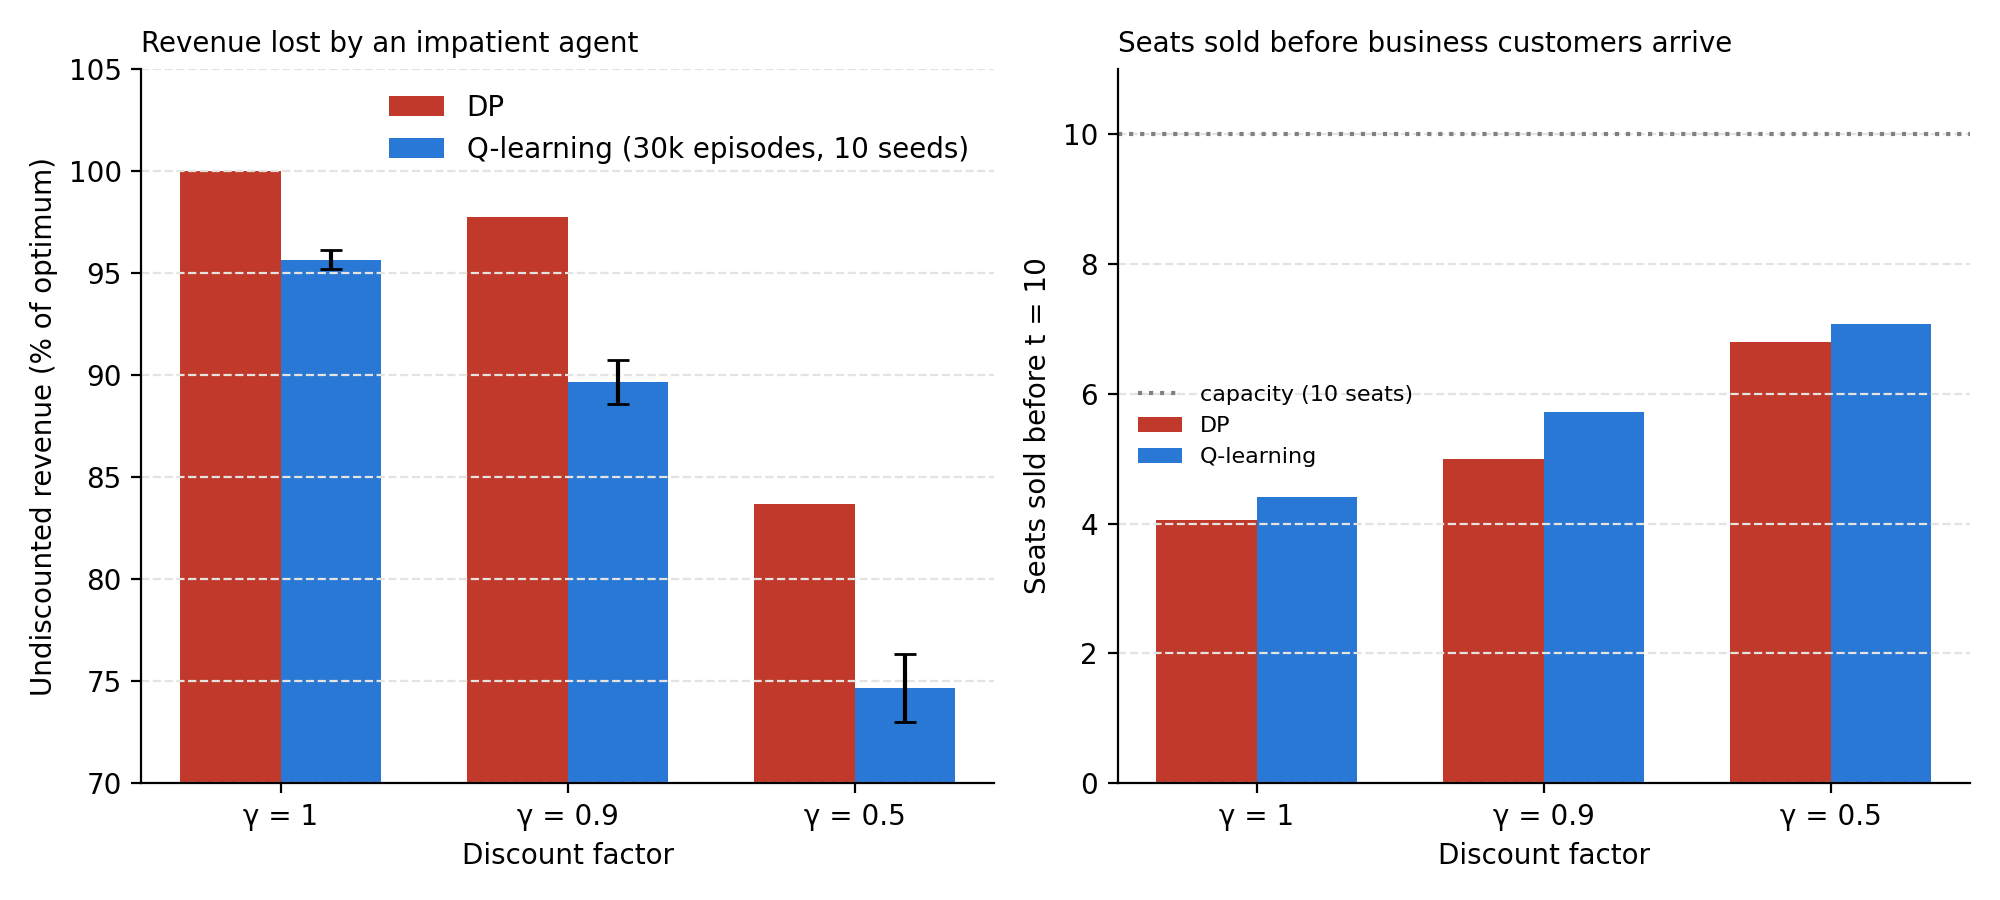

In [14]:
display(Image(os.path.join(FIGURES, "e4_comparison.png"), width=800))

With $\gamma = 0.5$ the agent becomes myopic: it sells seats to leisure customers before business
customers arrive (6.8 seats for the DP, 4.1 with $\gamma = 1$) and loses 16 % (DP) to 25 % (Q-learning) of the revenue.

## 6. Conclusion

- Learning beats planning only for large model errors (WTP under-estimated by 30 % or more, or
  over-estimated by 40 % or more), and only with $10^3$ to $3\cdot10^4$ flights.
- For moderate errors, planning with an imperfect model wins.
- Even with $10^5$ flights, tabular RL stays below a simple rising-price rule: a good model is worth the last few percent.
- Limits: synthetic demand, a single perturbed parameter, tabular methods (real aircraft would need
  value function approximation).